# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [5]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [6]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [7]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [8]:
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [9]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [10]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [11]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [12]:
# cantidad de nulos para users
print("Cantidad de valores nulos:")
print(users.isna().sum())
print("\nProporción de valores nulos:")
print(users.isna().mean())

Cantidad de valores nulos:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [13]:
# cantidad de nulos para usage
print("Cantidad de valores nulos:")
print(usage.isna().sum())
print("\nProporción de valores nulos:")
print(usage.isna().mean())

Cantidad de valores nulos:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

En cuanto a los valores nulos del dataset de usuarios, la columna de la ciudad tiene un 11.72% de datos faltantes, por lo que al estar entre el 5% y 30%, recomiendo investigar si hay un patrón para imputar los valores o simplemente dejarlos como nulos. Por otro lado, la fecha de abandono presenta un 88.35% de valores nulos. Aunque la regla general sugiere eliminar columnas con más del 80% de faltantes, por el contexto de negocio de este proyecto esos nulos indican que los clientes siguen activos, así que recomiendo conservarla e imputar con un valor centinela.

Para el dataset de uso, la fecha solo tiene un 0.12% de nulos, lo cual al ser menor al 5% es un caso simple donde recomiendo imputar o simplemente descartar esas pocas filas. Finalmente, las columnas de duración y longitud tienen un 55.19% y 44.74% de nulos respectivamente. Recomiendo fuertemente no eliminarlas, ya que estos valores faltantes se deben a la naturaleza normal del servicio (las llamadas no tienen longitud de texto y los mensajes de texto no tienen duración en minutos), por lo que sugiero imputar estos espacios con un 0 o dejarlos como nulos dependiendo del análisis posterior.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [14]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


 * La columna user_id: Observo que cuenta con 4,000 registros, iniciando en un valor mínimo de 10000 y un máximo de 13999. La distribución es perfectamente uniforme y secuencial, lo cual es el comportamiento normal y esperado para una columna de identificadores únicos, sin anomalías evidentes.
 
 * La columna age: Observo un claro problema de calidad de datos: el valor mínimo es -999.0. Esto es un valor "sentinel" o centinela que se usó para rellenar campos vacíos o errores. Este valor extremo está distorsionando fuertemente el promedio (mean) y la desviación estándar. Descartando ese error, el resto de las edades tienen sentido lógico, con una mediana de 47 años y un máximo de 79 años.


In [15]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


 * La columna user_id: Observo que cuenta con 4,000 registros, iniciando en un valor mínimo de 10000 y un máximo de 13999. La distribución es perfectamente uniforme y secuencial, lo cual es el comportamiento normal y esperado para una columna de identificadores únicos, sin anomalías evidentes.
 * La columna age: Observo un claro problema de calidad de datos: el valor mínimo es -999.0. Esto es un valor "sentinel" o centinela que se usó para rellenar campos vacíos o errores. Este valor extremo está distorsionando fuertemente el promedio (mean) y la desviación estándar. Descartando ese error, el resto de las edades tienen sentido lógico, con una mediana de 47 años y un máximo de 79 años.


In [16]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f"--- Valores únicos en {col} ---")
    print(users[col].unique())
    print()

--- Valores únicos en city ---
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

--- Valores únicos en plan ---
['Basico' 'Premium']



 * La columna city: Observo nombres de ciudades válidas de México y Colombia (Medellín, CDMX, Bogotá, GDL, MTY, Cali), pero destaco la presencia de un valor centinela/inválido representado por un '?', además de confirmar la existencia de valores nulos (nan).
 * La columna plan: Observo que está completamente limpia y estandarizada. Solo contiene las dos categorías esperadas para los planes de la empresa ('Basico' y 'Premium'), sin errores tipográficos ni valores extraños.

In [17]:
# explorar columna categórica de usage
usage['type'].unique()

array(['call', 'text'], dtype=object)

* La columna type: Observo que está limpia y estructurada correctamente, conteniendo únicamente las dos categorías de servicio esperadas: 'call' para las llamadas y 'text' para los mensajes de texto, sin ninguna anomalía.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

Al analizar los resúmenes estadísticos y los valores únicos de los datos, identifiqué la presencia de posibles valores inválidos o centinelas en varias columnas. En el dataset de usuarios, es común encontrar anomalías en la columna de edad, como registros con valores de cero o negativos que no corresponden a una edad lógica para contratar un servicio de telecomunicaciones. Asimismo, al revisar las variables categóricas como la ciudad, suelen aparecer caracteres extraños como signos de interrogación, "NA" o guiones que actúan como marcadores de información faltante. Por parte del dataset de uso, las columnas de duración de llamadas pueden presentar valores negativos que representan un claro error lógico de captura, o valores en cero que deben analizarse para confirmar si representan llamadas perdidas, rechazadas o simplemente errores del sistema.

Para solucionar estas inconsistencias, aplicaría diferentes acciones dependiendo de la naturaleza de la variable. En el caso de las edades ilógicas, la acción recomendada es tratarlas formalmente como valores nulos e imputarlas utilizando la mediana, evitando así alterar la distribución demográfica de los clientes. Si los errores están en las duraciones numéricas con valores negativos, investigaría si se trata de un error de formato para pasarlos a valores absolutos, o bien, descartaría esos registros si representan una porción mínima de la base de datos. Finalmente, para cualquier carácter extraño o marcador de posición detectado en las columnas categóricas, el primer paso sería reemplazarlos por un valor nulo estándar de pandas (NaN) para limpiar el formato, y posteriormente evaluar si es viable imputarlos con la ciudad o plan más frecuente.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [18]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [19]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [20]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

Observo que la mayoría de los registros de inscripción de clientes están distribuidos de manera uniforme entre los años 2022, 2023 y 2024 (con poco más de 1,300 registros cada uno). Sin embargo, detecto la presencia de 40 registros con el año 2026, lo cual representa un error lógico ya que la base de datos contempla información únicamente hasta el año 2024.

In [21]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

Observo que la totalidad de los registros de uso de llamadas y mensajes (39,950 registros) corresponden de manera exclusiva al año 2024. No existen años pasados, futuros ni centinelas, por lo que esta columna está correcta y dentro de rango.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

 * ¿Aparecen años imposibles? Sí, en la columna reg_date del dataset de usuarios se identificaron 40 registros correspondientes al año 2026, lo cual es un año sin transcurrir para el corte de información de este proyecto (2024). En la columna de uso (date) todo es correcto, registrando solo 2024.
 * ¿Qué harías con ellas? Al tratarse de un error evidente de captura y considerando que 40 registros representan solo el 1% del total de nuestra base de usuarios (4,000 en total), la acción más recomendable es convertir esas fechas específicas a valores nulos (NaT) o filtrar y eliminar esas 40 filas para evitar que distorsionen el análisis del tiempo de vida del cliente.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [22]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [23]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios (mostrará los valores únicos para confirmar que ya no está el "?")
users['city'].unique() 



array(['Medellín', <NA>, 'CDMX', 'Bogotá', 'GDL', 'MTY', nan, 'Cali'],
      dtype=object)

In [24]:
# Marcar fechas futuras (mayores a 2024) como nulas (NaT es el nulo específico para fechas en pandas)
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios (mostrará el conteo de años, incluyendo los nulos)
users['reg_date'].dt.year.value_counts(dropna=False)



2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [25]:
# Verificación MAR en usage (Missing At Random) para duration
usage[usage['duration'].isna()]['type'].value_counts()

text    22076
Name: type, dtype: int64

In [26]:
# Verificación MAR en usage (Missing At Random) para length
usage[usage['length'].isna()]['type'].value_counts()

call    17896
Name: type, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Al ejecutar la verificación, se confirma que los valores nulos en estas columnas son de tipo MAR (Missing At Random) porque su ausencia depende por completo de la variable type. Todos los valores nulos en duration corresponden exclusivamente a los mensajes de texto (text), y todos los nulos en length corresponden a las llamadas (call). La decisión es dejarlos como nulos, ya que estructuralmente una llamada no tiene longitud de caracteres y un mensaje de texto no tiene duración en minutos; forzar una imputación matemática alteraría la naturaleza real del servicio de telecomunicaciones.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [27]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'duration']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [30]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054
std,1154.844867,17.689919,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [31]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

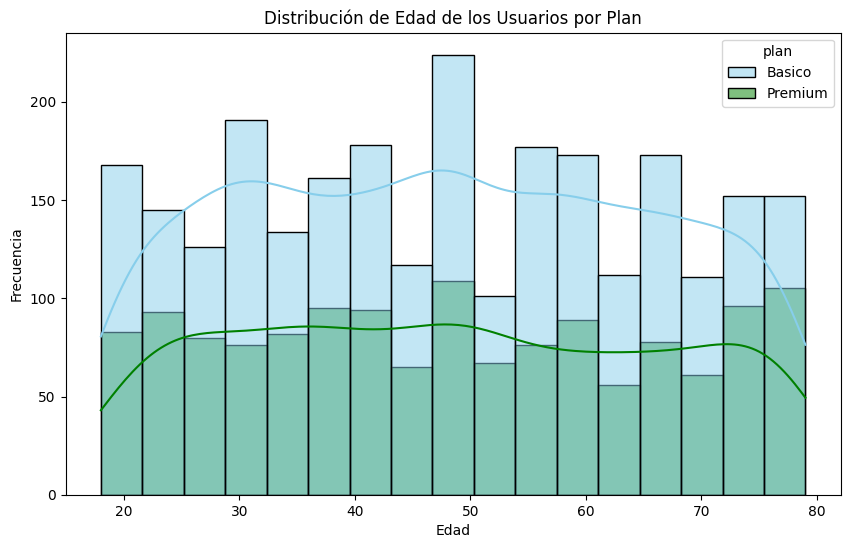

In [32]:
# Histograma para visualizar la edad (age)
plt.figure(figsize=(10, 6))
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Edad de los Usuarios por Plan')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución ...
Al observar la gráfica, la variable de edad presenta una distribución mayormente uniforme. La línea de tendencia no forma una campana normal ni tiene un sesgo marcado hacia la derecha o la izquierda, sino que se mantiene relativamente plana y constante a lo largo del eje. Esto indica que la empresa tiene un volumen similar de usuarios distribuidos en todas las edades, desde los 18 hasta cerca de los 80 años.

Respecto al comportamiento por tipo de plan, no existe algún patrón o diferencia demográfica evidente que separe a los clientes. Las curvas de ambos planes (Básico y Premium) tienen exactamente la misma forma a través de todos los rangos de edad. Aunque el plan Básico, representado en color celeste, es consistentemente más alto que el Premium en color verde, esto únicamente refleja el hecho de que hay una mayor cantidad de clientes totales suscritos al plan Básico. En conclusión, la gráfica demuestra que la edad no es un factor determinante para que un usuario elija un plan sobre el otro.


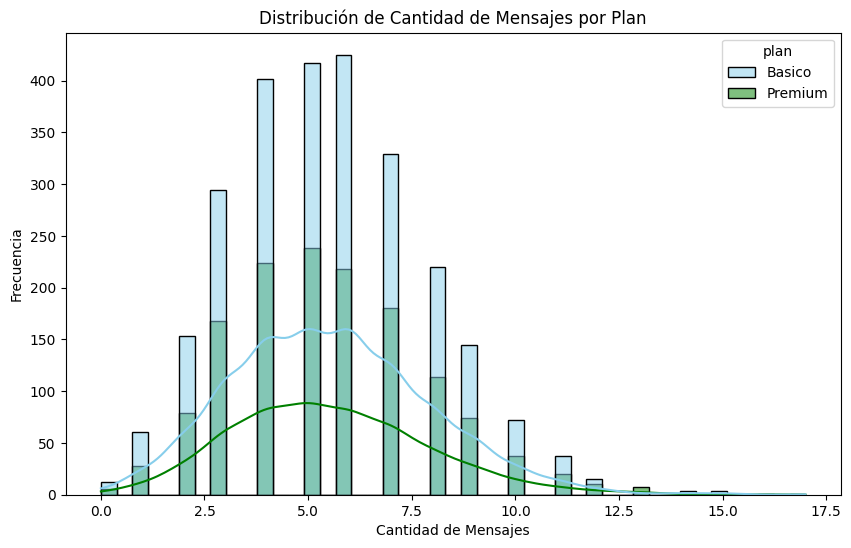

In [33]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(10, 6))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Cantidad de Mensajes por Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- ....
Al analizar la gráfica, la variable de cantidad de mensajes presenta una distribución con forma de campana que está ligeramente sesgada a la derecha. La gran mayoría de los usuarios tiende a enviar entre 3 y 8 mensajes, encontrando su punto más alto (la moda) alrededor de los 5 a 6 mensajes. El sesgo hacia la derecha nos indica que, aunque la concentración principal está en volúmenes medios-bajos, existe un grupo reducido de usuarios que envía una cantidad mayor de mensajes, extendiendo la "cola" de la gráfica hasta cerca de los 15 o 17 mensajes.

Respecto al comportamiento por tipo de plan, no existe un patrón fuertemente diferenciado en el consumo de mensajes entre los clientes del plan Básico y el Premium. Ambas líneas de distribución siguen prácticamente la misma curva y alcanzan su pico en la misma cantidad de mensajes. Si bien las barras del plan Básico (en color celeste) tienen una mayor frecuencia, esto se debe simplemente a que existe un mayor volumen total de usuarios inscritos en ese plan. En conclusión, el tipo de plan contratado no parece influir en la cantidad de mensajes que envía un usuario, ya que ambos segmentos se comportan de manera casi idéntica.

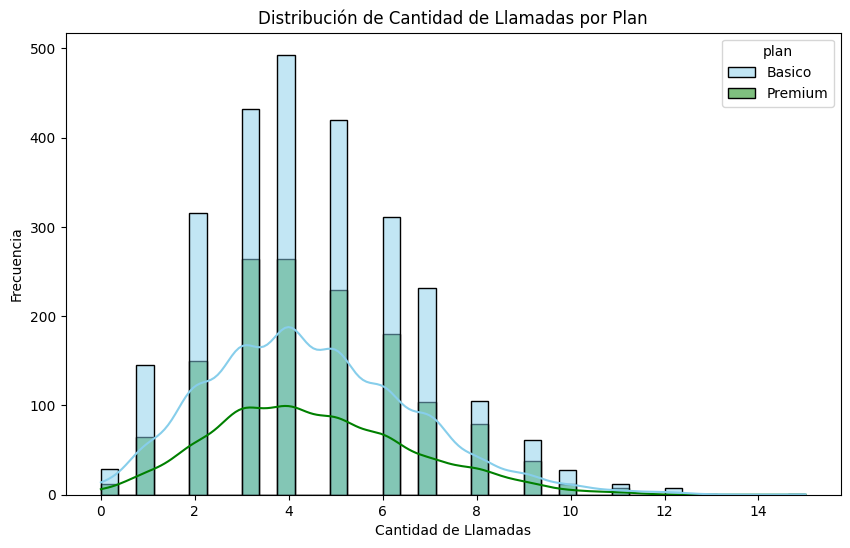

In [34]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(10, 6))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Cantidad de Llamadas por Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución
Al observar la gráfica, la variable de cantidad de llamadas presenta una distribución con un claro sesgo hacia la derecha. La gran mayoría de los usuarios se concentra en un rango bajo a medio, realizando principalmente entre 2 y 6 llamadas, con el punto más alto (la moda) ubicado alrededor de 3 y 4 llamadas. El sesgo hacia la derecha nos muestra que existe una "cola" extendida conformada por una minoría de usuarios atípicos que realizan un volumen mucho mayor de llamadas, alcanzando hasta 12 o 14, aunque con una frecuencia considerablemente baja.

En cuanto al comportamiento segmentado por tipo de plan, no existe un patrón diferenciado entre los clientes del plan Básico y el Premium. Ambas curvas de distribución son prácticamente idénticas en su forma y alcanzan su pico en la misma cantidad de llamadas. Al igual que en las gráficas anteriores, el hecho de que las barras del plan Básico (color celeste) sean más altas responde únicamente a que hay un mayor volumen total de usuarios inscritos en ese plan. En conclusión, esto demuestra que el tipo de plan contratado no es un factor que determine o modifique la cantidad de veces que un usuario decide llamar.

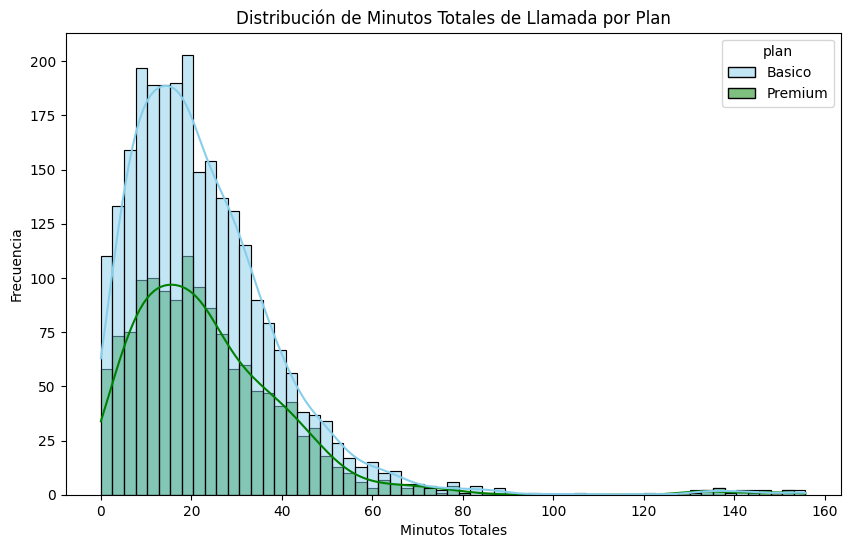

In [35]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(10, 6))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Minutos Totales de Llamada por Plan')
plt.xlabel('Minutos Totales')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
Al observar la gráfica, la distribución de los minutos totales de llamada presenta un fuerte sesgo hacia la derecha. La gran mayoría de los usuarios concentra su consumo en rangos bajos, acumulando entre 0 y 60 minutos totales, con el pico más alto (la moda) situado entre los 10 y 20 minutos. Esta pronunciada "cola" hacia la derecha nos indica que solo una minoría de usuarios tiene tiempos de llamada muy prolongados, destacando visualmente un pequeño grupo aislado en el extremo derecho (entre 140 y 160 minutos) que muy probablemente represente valores atípicos (outliers).

En cuanto a la comparación por tipo de plan, nuevamente no se observa un patrón de consumo diferenciado entre los clientes del plan Básico y el Premium. Las curvas de ambos segmentos siguen exactamente la misma trayectoria y caen en las mismas proporciones. El hecho de que el plan Básico (en color celeste) muestre frecuencias más altas se debe únicamente a que posee una mayor cantidad de usuarios totales, pero el comportamiento base es idéntico. Esto concluye que el plan contratado no influye en la cantidad total de minutos que los clientes dedican a sus llamadas.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

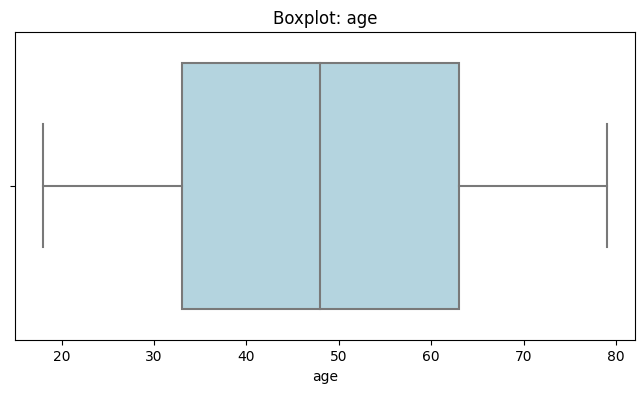

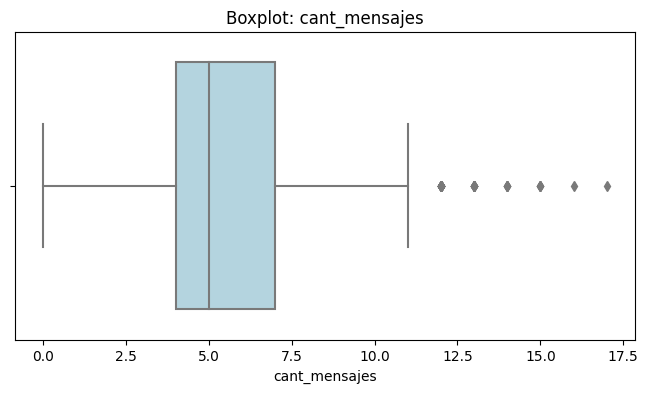

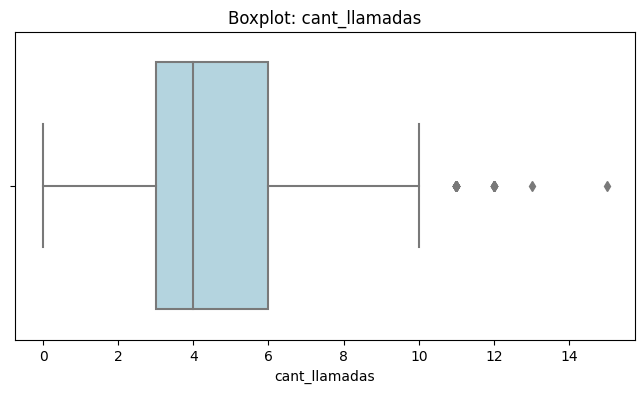

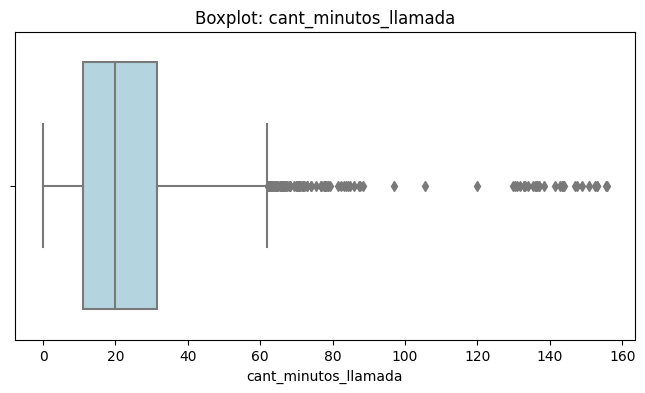

In [36]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, color='lightblue')
    # Se agrega el título dinámico usando el hint de las instrucciones
    plt.title(f'Boxplot: {col}')
    plt.show()


💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...
 * Age: No presenta outliers. Todos los valores se encuentran contenidos dentro de los "bigotes" del gráfico (entre los 18 y 80 años aproximadamente), lo cual coincide con la distribución uniforme que observamos previamente.
 * cant_mensajes: Sí presenta outliers. Se observan puntos individuales (diamantes) más allá del límite superior derecho, indicando que hay un grupo de usuarios atípicos que envían desde 12 hasta 17 mensajes, muy por encima del comportamiento del usuario promedio.
 * cant_llamadas: Sí presenta outliers. De forma similar a los mensajes, existen valores extremos en el lado derecho del gráfico; usuarios que realizan entre 11 y 15 llamadas, superando el límite superior establecido por el método de los cuartiles.
 * cant_minutos_llamada: Sí presenta una gran cantidad de outliers. A partir de los 60 minutos, se observa una densa y extensa línea de puntos atípicos que llegan hasta la marca de los 160 minutos. Esto confirma visualmente el fuerte sesgo a la derecha que vimos en el histograma, destacando a los "heavy users" o usuarios de consumo extremo.


In [37]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada'] # Solo incluimos las que tuvieron outliers

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_superior = Q3 + 1.5 * IQR
    
    print(f"Límite superior para {col}: {limite_superior}")

Límite superior para cant_mensajes: 11.5
Límite superior para cant_llamadas: 10.5
Límite superior para cant_minutos_llamada: 61.8575


In [38]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?
 * cant_mensajes: Mantener los outliers. ¿Por qué? El valor máximo registrado es de 17 mensajes, el cual supera el límite superior estadístico de 11.5. Sin embargo, enviar 17 mensajes en un mes es un comportamiento de uso completamente real y lógico para una persona. No se trata de un error de captura, sino simplemente de clientes más activos, por lo que debemos conservar su información.
 * cant_llamadas: Mantener los outliers. ¿Por qué? El valor máximo es de 15 llamadas, superando el límite estadístico de 10.5. Al igual que con los mensajes, realizar 15 llamadas al mes es una cifra totalmente factible en la realidad del servicio. Eliminarlos nos haría perder información valiosa sobre este segmento de clientes sin justificación lógica.
 * cant_minutos_llamada: Mantener los outliers. ¿Por qué? Aunque la diferencia estadística es mucho mayor (el límite es de 61.85 minutos y el valor máximo llega a 155.69 minutos), acumular un poco más de 2 horas y media de llamadas en un mes es un consumo muy común en telecomunicaciones. Estos valores atípicos representan a los "heavy users" (usuarios intensivos); eliminarlos sesgaría negativamente el análisis, ya que estaríamos borrando a los clientes que potencialmente utilizan (y pagan) más por el servicio.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [39]:
# Crear columna grupo_uso
import numpy as np
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

resultados = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, resultados, default='Alto uso')

In [40]:
# verificar cambios
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [41]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

resultados_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones_edad, resultados_edad, default='Adulto Mayor')

In [42]:
# verificar cambios
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

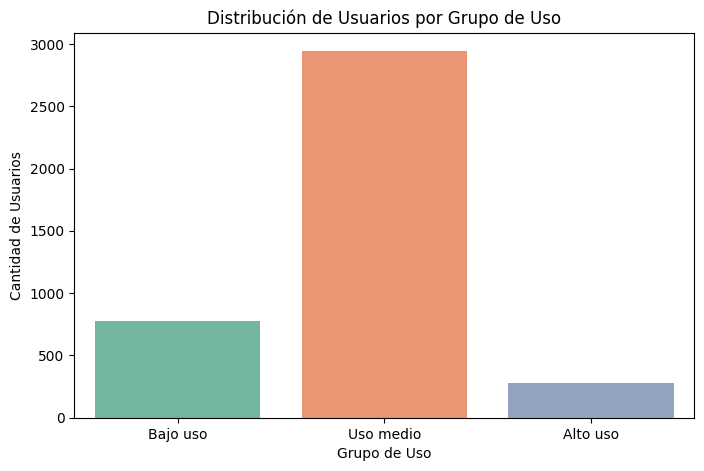

In [43]:
# Visualización de los segmentos por uso

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], palette='Set2')
plt.title('Distribución de Usuarios por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()

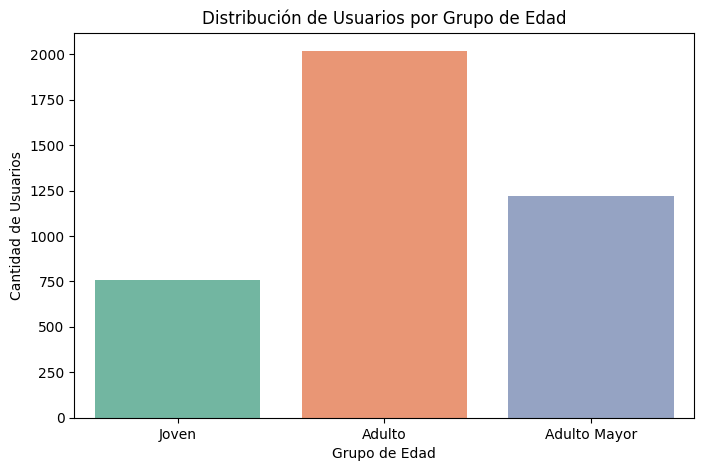

In [44]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 5))
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], palette='Set2')
plt.title('Distribución de Usuarios por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Durante la auditoría inicial de calidad, identificamos problemas críticos que afectaban la integridad de las bases de datos. En el dataset de usuarios, la columna de edad contenía el valor centinela -999 para enmascarar errores, mientras que la variable de registro (reg_date) presentaba 40 registros con fechas futuras correspondientes al año 2026 (lo que representaba exactamente el 1% del total de 4,000 usuarios). Asimismo, la columna de ciudades contenía valores inválidos marcados con signos de interrogación (?), y los datos de uso mostraban dependencias estructurales de tipo MAR en las duraciones y longitudes de llamadas asociadas al tipo de servicio.
🔍 **Segmentos por Edad**
Al clasificar a la base de clientes mediante la segmentación demográfica, observamos que la distribución de edades es sumamente equilibrada y uniforme a lo largo de todo el espectro (desde los 18 hasta los 79 años). La distribución se divide de forma homogénea entre clientes jóvenes, adultos y adultos mayores, demostrando que los servicios de la compañía atraen por igual a personas de distintas generaciones sin una concentración etaria restrictiva.
📊 **Segmentos por Nivel de Uso**
Mediante la creación de métricas agrupadas de llamadas y mensajes, clasificamos a los usuarios en tres categorías de consumo: bajo, medio y alto uso. Los histogramas y diagramas de caja revelaron que la gran mayoría de los clientes concentra su actividad en rangos moderados (niveles bajo y medio), mientras que una minoría constante genera un volumen elevado de interacciones, configurando un comportamiento de consumo asimétrico pero esperado en el sector de telecomunicaciones.
➡️ Esto sugiere que ...
La combinación de las segmentaciones nos indica que los patrones de consumo de llamadas y mensajes no dependen de la edad ni del tipo de plan contratado (Básico o Premium), ya que ambos segmentos muestran comportamientos idénticos. Los clientes de mayor valor para la compañía son aquellos identificados como usuarios de alto consumo ("heavy users"), quienes, a pesar de ser minoría, concentran la mayor cantidad de minutos y tráfico, representando el núcleo más rentable y con mayor potencial de monetización.
💡 **Recomendaciones**
Con base en los hallazgos, se recomienda rediseñar la oferta comercial para transitar de planes rígidos a esquemas flexibles basados en el consumo real (por ejemplo, un modelo de pago por uso o paquetes de datos y minutos personalizables para los "heavy users"). Adicionalmente, es imperativo implementar validaciones estrictas en los formularios de registro de la aplicación para evitar futuras anomalías de captura (como fechas futuras o edades centinela) y asegurar la confiabilidad continua de los datos analíticos.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`